In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv('/content/customer-churn-training.csv')

print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/customer-churn-training.csv'

In [3]:
import os

print(os.listdir('/content'))

['.config', 'customer-churn-training (1).csv', 'sample_data']


In [4]:
df = pd.read_csv('/content/customer-churn-training(1).csv')

print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/customer-churn-training(1).csv'

In [5]:
import pandas as pd

df = pd.read_csv('customer-churn-training(1).csv')

print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'customer-churn-training(1).csv'

In [6]:
import os

print(os.getcwd())
print(os.listdir('/content'))

/content
['.config', 'customer-churn-training (1).csv', 'sample_data']


In [7]:
df = pd.read_csv('/content/customer-churn-training (1).csv')

print(df.head())

  customer_id  tenure_months  support_tickets  monthly_spend_inr  \
0        C001              2                4                499   
1        C002             18                1               1299   
2        C003              6                3                799   
3        C004             30                0               1499   
4        C005             11                2                999   

   last_login_days plan_type  churned  
0               21     Basic        1  
1                2       Pro        0  
2               14     Basic        1  
3                1       Pro        0  
4                5  Standard        0  


In [8]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(12, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   customer_id        12 non-null     object
 1   tenure_months      12 non-null     int64 
 2   support_tickets    12 non-null     int64 
 3   monthly_spend_inr  12 non-null     int64 
 4   last_login_days    12 non-null     int64 
 5   plan_type          12 non-null     object
 6   churned            12 non-null     int64 
dtypes: int64(5), object(2)
memory usage: 804.0+ bytes
None

Missing Values:
customer_id          0
tenure_months        0
support_tickets      0
monthly_spend_inr    0
last_login_days      0
plan_type            0
churned              0
dtype: int64


In [9]:
print("Customer Churn Count:")

print(df['churned'].value_counts())

print("\nChurn Percentage:")

print(df['churned'].value_counts(normalize=True) * 100)

Customer Churn Count:
churned
0    7
1    5
Name: count, dtype: int64

Churn Percentage:
churned
0    58.333333
1    41.666667
Name: proportion, dtype: float64


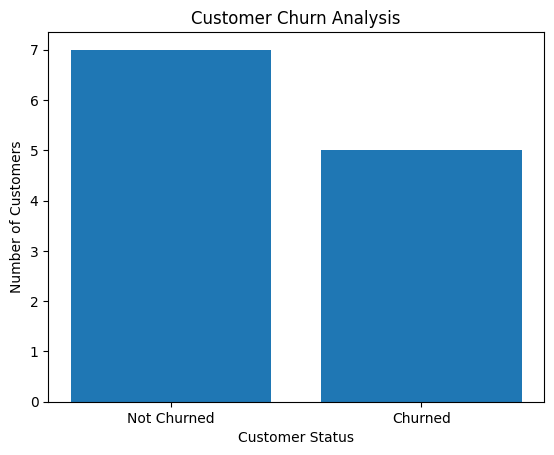

In [10]:
import matplotlib.pyplot as plt

churn_counts = df['churned'].value_counts()

plt.bar(['Not Churned', 'Churned'], churn_counts.sort_index())

plt.title('Customer Churn Analysis')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')

plt.show()

In [11]:
print("Average Customer Details:")

print(df.groupby('churned')[[
    'tenure_months',
    'support_tickets',
    'monthly_spend_inr',
    'last_login_days'
]].mean())

Average Customer Details:
         tenure_months  support_tickets  monthly_spend_inr  last_login_days
churned                                                                    
0            17.857143         1.142857        1127.571429         3.714286
1             4.200000         3.800000         619.000000        18.800000


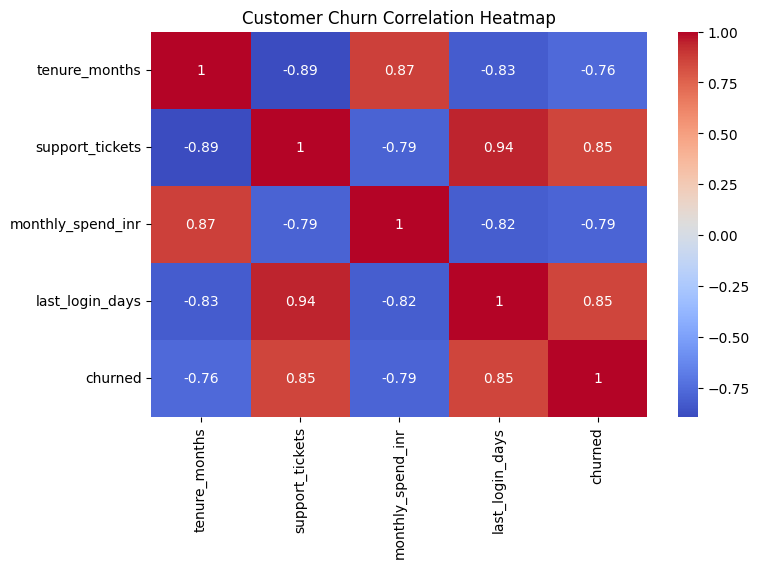

In [12]:
correlation = df.select_dtypes(include='number').corr()

plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm')

plt.title('Customer Churn Correlation Heatmap')
plt.show()

In [13]:
X = df.drop('churned', axis=1)
y = df['churned']

In [14]:
X = pd.get_dummies(X, columns=['plan_type'], drop_first=True, dtype=int)

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

NameError: name 'train_test_split' is not defined

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [18]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

ValueError: could not convert string to float: 'C002'

In [19]:
X = X.drop('customer_id', axis=1)

In [20]:
model.fit(X_train, y_train)

ValueError: could not convert string to float: 'C002'

In [21]:
X = X.drop('customer_id', axis=1)

KeyError: "['customer_id'] not found in axis"

In [22]:
X = pd.get_dummies(
    df.drop(columns=['customer_id', 'churned']),
    columns=['plan_type'],
    drop_first=True,
    dtype=int
)

y = df['churned']

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [24]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [25]:
y_pred = model.predict(X_test)

In [26]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 66.66666666666666 %


In [27]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.50      0.67         2
           1       0.50      1.00      0.67         1

    accuracy                           0.67         3
   macro avg       0.75      0.75      0.67         3
weighted avg       0.83      0.67      0.67         3



In [28]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred))

[[1 1]
 [0 1]]


In [29]:
import joblib

joblib.dump(model, 'customer_churn_model.pkl')

['customer_churn_model.pkl']

In [30]:
from google.colab import files

files.download('customer_churn_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>